Васильев Кирилл


In [1]:

%pip install -q kagglehub

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchvision
import kagglehub

from pathlib import Path
from PIL import Image
from torch import nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

RANDOM_STATE = 17

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12
})

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4



Загрузка и исследование набора данных


In [2]:

DATASET_ID = (
    "maysee/mushrooms-classification-common-genuss-images"
)

dataset_path = kagglehub.dataset_download(DATASET_ID)

DATA_DIR = Path(dataset_path)

print("Датасет загружен")
print("Расположение:", DATA_DIR)

assert DATA_DIR.exists(), "Папка датасета не найдена"

print("Содержимое корневой директории:\n")

for item in sorted(DATA_DIR.iterdir()):
    print(
        "📁" if item.is_dir() else "📄",
        item.name
    )

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

image_paths = [
    path for path in DATA_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in image_extensions
]

print("\nКоличество найденных изображений:",
      len(image_paths))

print("\nПримеры путей:")
for path in image_paths[:5]:
    print(path.relative_to(DATA_DIR))

Using Colab cache for faster access to the 'mushrooms-classification-common-genuss-images' dataset.
Датасет загружен
Расположение: /kaggle/input/mushrooms-classification-common-genuss-images
Содержимое корневой директории:

📁 Mushrooms
📁 mushrooms

Количество найденных изображений: 13428

Примеры путей:
mushrooms/Mushrooms/Entoloma/126_-P40YY9dxnU.jpg
mushrooms/Mushrooms/Entoloma/092_C-d5aHykeOY.jpg
mushrooms/Mushrooms/Entoloma/033_yJBfhGv9URU.jpg
mushrooms/Mushrooms/Entoloma/154_HDT_he4bSpA.jpg
mushrooms/Mushrooms/Entoloma/159_gzyo4cu2SF0.jpg



анализ структуры датасета

In [3]:

from collections import Counter

folder_counts = Counter(
    str(path.parent.relative_to(DATA_DIR))
    for path in image_paths
)

print("Количество папок с изображениями:",
      len(folder_counts))

print("\nРаспределение изображений:\n")

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count}")

print("\nВсего изображений:",
      sum(folder_counts.values()))

Количество папок с изображениями: 18

Распределение изображений:

Mushrooms/Agaricus: 353
Mushrooms/Amanita: 750
Mushrooms/Boletus: 1073
Mushrooms/Cortinarius: 836
Mushrooms/Entoloma: 364
Mushrooms/Hygrocybe: 316
Mushrooms/Lactarius: 1563
Mushrooms/Russula: 1148
Mushrooms/Suillus: 311
mushrooms/Mushrooms/Agaricus: 353
mushrooms/Mushrooms/Amanita: 750
mushrooms/Mushrooms/Boletus: 1073
mushrooms/Mushrooms/Cortinarius: 836
mushrooms/Mushrooms/Entoloma: 364
mushrooms/Mushrooms/Hygrocybe: 316
mushrooms/Mushrooms/Lactarius: 1563
mushrooms/Mushrooms/Russula: 1148
mushrooms/Mushrooms/Suillus: 311

Всего изображений: 13428


Анализ структуры и повторяемости данных

In [4]:

import filecmp

root_a = DATA_DIR / "Mushrooms"
root_b = DATA_DIR / "mushrooms" / "Mushrooms"

def get_files(root):
    return {
        p.relative_to(root): p
        for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    }

files_a = get_files(root_a)
files_b = get_files(root_b)

common = set(files_a) & set(files_b)

identical = sum(
    filecmp.cmp(
        files_a[name],
        files_b[name],
        shallow=False
    )
    for name in common
)

print("Каталог A:", len(files_a))
print("Каталог B:", len(files_b))
print("Общие пути:", len(common))
print("Идентичные файлы:", identical)

if (
    len(files_a) == len(files_b) == len(common)
    and identical == len(common)
):
    DATASET_ROOT = root_a
    print("\nКаталоги идентичны.")
    print("Используем:", DATASET_ROOT)
else:
    raise ValueError(
        "Каталоги различаются. "
        "Нужно дополнительно исследовать данные."
    )

Каталог A: 6714
Каталог B: 6714
Общие пути: 6714
Идентичные файлы: 6714

Каталоги идентичны.
Используем: /kaggle/input/mushrooms-classification-common-genuss-images/Mushrooms


проверка дублирования данных

Всего изображений: 6714
Количество классов: 9

Названия классов:
['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']


,Genus,Images
0,Agaricus,353
1,Amanita,750
2,Boletus,1073
3,Cortinarius,836
4,Entoloma,364
5,Hygrocybe,316
6,Lactarius,1563
7,Russula,1148
8,Suillus,311


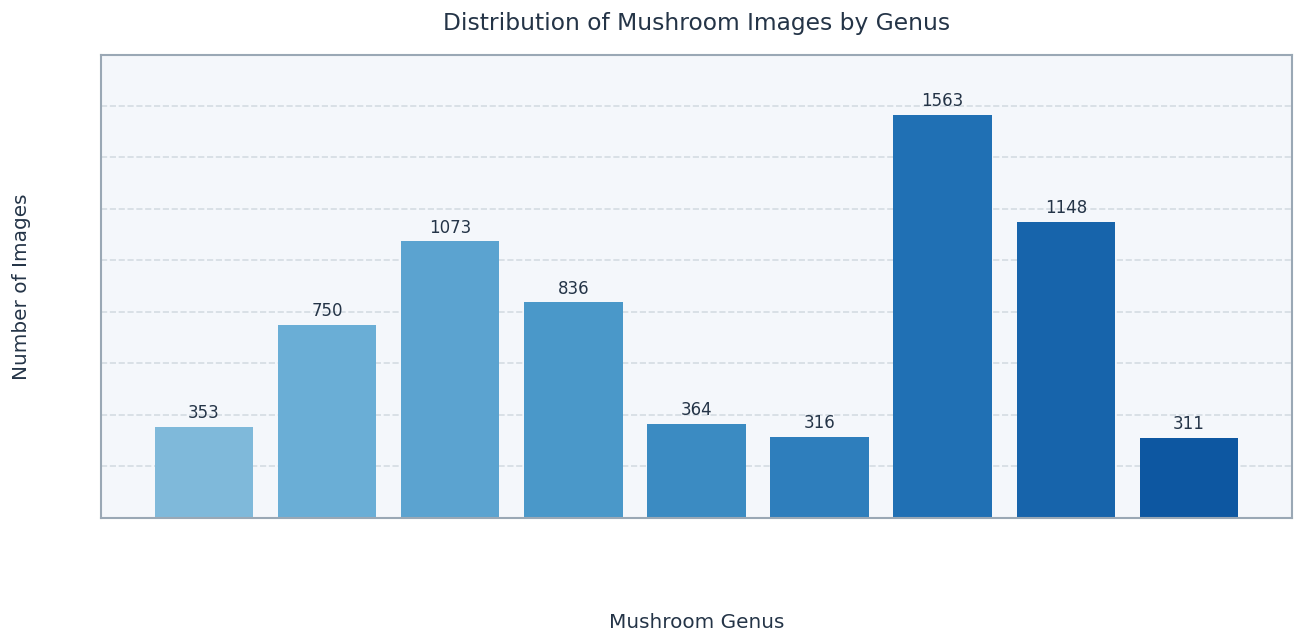

In [5]:

from torchvision import datasets
from collections import Counter

mushroom_dataset = datasets.ImageFolder(
    root=DATASET_ROOT
)

class_names = mushroom_dataset.classes

num_classes = len(class_names)

class_counts = Counter(mushroom_dataset.targets)

class_distribution = pd.DataFrame({
    "Genus": class_names,
    "Images": [
        class_counts[i] for i in range(num_classes)
    ]
})

print("Всего изображений:", len(mushroom_dataset))
print("Количество классов:", num_classes)
print("\nНазвания классов:")
print(class_names)

display(class_distribution)


import matplotlib.pyplot as plt
import numpy as np

genus = class_distribution["Genus"]
images = class_distribution["Images"]

colors = plt.cm.Blues(np.linspace(0.45, 0.85, len(genus)))

fig, ax = plt.subplots(figsize=(11, 5.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("#f4f7fb")

bars = ax.bar(genus, images, color=colors, edgecolor="none", linewidth=1)

ax.set_title(
    "Distribution of Mushroom Images by Genus",
    color="#243447",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Mushroom Genus", color="#243447")
ax.set_ylabel("Number of Images", color="#243447")

ax.tick_params(axis="x", colors="white", rotation=35)
ax.tick_params(axis="y", colors="white")

for spine in ax.spines.values():
    spine.set_color("#9aa8b5")

ax.grid(axis="y", color="#9aa8b5", alpha=0.35, linestyle="--")

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 20,
        f"{int(height)}",
        ha="center",
        va="bottom",
        color="#243447",
        fontsize=10
    )

ax.set_ylim(0, max(images) * 1.15)

ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

 Подготовка данных для обучения



In [6]:

import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for idx, (path, label) in enumerate(mushroom_dataset.samples):

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            sha256.update(chunk)

    file_hash = sha256.hexdigest()
    hash_groups[file_hash].append(idx)

duplicate_groups = {
    h: indices
    for h, indices in hash_groups.items()
    if len(indices) > 1
}

extra_copies = sum(
    len(indices) - 1
    for indices in duplicate_groups.values()
)

conflicting_groups = [
    indices
    for indices in duplicate_groups.values()
    if len({
        mushroom_dataset.targets[i]
        for i in indices
    }) > 1
]

print("Всего изображений:", len(mushroom_dataset))
print("Уникальных файлов:", len(hash_groups))
print("Групп дубликатов:", len(duplicate_groups))
print("Лишних копий:", extra_copies)
print("Дубликатов между классами:",
      len(conflicting_groups))

Всего изображений: 6714
Уникальных файлов: 6645
Групп дубликатов: 69
Лишних копий: 69
Дубликатов между классами: 0



Формирование обучающей, валидационной и тестовой выборок

In [7]:
from sklearn.model_selection import train_test_split

unique_indices = np.asarray(
    [group[0] for group in hash_groups.values()],
    dtype=int
)
unique_targets = np.asarray([
    mushroom_dataset.targets[i] for i in unique_indices
])

train_validation_idx, test_idx = train_test_split(
    unique_indices,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=unique_targets
)

remaining_targets = np.asarray([
    mushroom_dataset.targets[i] for i in train_validation_idx
])
validation_fraction = 0.10 / 0.85

train_idx, validation_idx = train_test_split(
    train_validation_idx,
    test_size=validation_fraction,
    random_state=RANDOM_STATE,
    stratify=remaining_targets
)

train_set = set(train_idx)
validation_set = set(validation_idx)
test_set = set(test_idx)

assert train_set.isdisjoint(validation_set)
assert train_set.isdisjoint(test_set)
assert validation_set.isdisjoint(test_set)
assert len(train_set | validation_set | test_set) == len(unique_indices)

split_summary = pd.DataFrame({
    "Подвыборка": ["Train", "Validation", "Test"],
    "Количество": [len(train_idx), len(validation_idx), len(test_idx)],
    "Доля, %": [
        100 * len(train_idx) / len(unique_indices),
        100 * len(validation_idx) / len(unique_indices),
        100 * len(test_idx) / len(unique_indices),
    ]
})

display(split_summary.style.format({"Доля, %": "{:.2f}"}))
print("Общее количество уникальных изображений:", len(unique_indices))
print("Проверка пересечений пройдена.")

,Подвыборка,Количество,"Доля, %"
0,Train,4983,74.99
1,Validation,665,10.01
2,Test,997,15.00


Общее количество уникальных изображений: 6645
Проверка пересечений пройдена.


 Предобработка изображений для ResNet18

In [8]:

from torchvision import transforms, models
from torch.utils.data import Dataset
from PIL import Image

weights = models.ResNet18_Weights.DEFAULT

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.75, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

eval_transform = weights.transforms()

class MushroomSubset(Dataset):

    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        original_idx = int(self.indices[idx])

        path, label = self.base_dataset.samples[original_idx]

        with Image.open(path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        return image, label

train_dataset = MushroomSubset(
    mushroom_dataset, train_idx, train_transform
)

validation_dataset = MushroomSubset(
    mushroom_dataset, validation_idx, eval_transform
)

test_dataset = MushroomSubset(
    mushroom_dataset, test_idx, eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))
print("Transforms configured successfully")

from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 2
loader_generator = torch.Generator()
loader_generator.manual_seed(RANDOM_STATE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    generator=loader_generator
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    generator=loader_generator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    generator=loader_generator
)

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Number of classes:", num_classes)

assert images.shape[1:] == (3, 224, 224)
assert labels.min() >= 0
assert labels.max() < num_classes

print("DataLoader verification successful")

Train: 4983
Validation: 665
Test: 997
Transforms configured successfully
Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Number of classes: 9
DataLoader verification successful



Контроль целостности изображений

In [9]:

from PIL import Image, ImageFile
from torch.utils.data import DataLoader
import numpy as np

ImageFile.LOAD_TRUNCATED_IMAGES = False

bad_indices = set()

for idx in unique_indices:
    idx = int(idx)
    path, label = mushroom_dataset.samples[idx]

    try:
        with Image.open(path) as img:
            img.convert("RGB").load()

    except Exception as error:
        bad_indices.add(idx)
        print(f"Повреждённый файл: {path}")
        print(f"Причина: {error}\n")

print("Проверено изображений:", len(unique_indices))
print("Повреждённых изображений:", len(bad_indices))

def remove_bad_indices(indices):
    return np.array([
        int(i) for i in indices
        if int(i) not in bad_indices
    ], dtype=int)

train_idx = remove_bad_indices(train_idx)
validation_idx = remove_bad_indices(validation_idx)
test_idx = remove_bad_indices(test_idx)

train_dataset = MushroomSubset(
    mushroom_dataset, train_idx, train_transform
)

validation_dataset = MushroomSubset(
    mushroom_dataset, validation_idx, eval_transform
)

test_dataset = MushroomSubset(
    mushroom_dataset, test_idx, eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    generator=loader_generator
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    generator=loader_generator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    generator=loader_generator
)

print("\nОбновлённые выборки:")
print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))
print("Всего:", (
    len(train_dataset)
    + len(validation_dataset)
    + len(test_dataset)
))

print("\nПодготовка данных завершена.")

Повреждённый файл: /kaggle/input/mushrooms-classification-common-genuss-images/Mushrooms/Russula/092_43B354vYxm8.jpg
Причина: image file is truncated (92 bytes not processed)

Проверено изображений: 6645
Повреждённых изображений: 1

Обновлённые выборки:
Train: 4983
Validation: 665
Test: 996
Всего: 6644

Подготовка данных завершена.


Разработка нейросетевой модели;
Архитектура ResNet18;
Метод Transfer Learning;

In [10]:


weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features

model.fc = nn.Linear(
    in_features=num_features,
    out_features=num_classes
)

model = model.to(device)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Architecture: ResNet18")
print("Device:", device)
print("Input features:", num_features)
print("Output classes:", num_classes)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("\nClassifier:")
print(model.fc)

model.eval()

images, labels = next(iter(train_loader))

sample_images = images[:2].to(device)

with torch.inference_mode():
    outputs = model(sample_images)

print("Input shape:", tuple(sample_images.shape))
print("Output shape:", tuple(outputs.shape))

assert outputs.shape == (2, num_classes)

print("ResNet18 forward pass successful")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 157MB/s]


Architecture: ResNet18
Device: cuda
Input features: 512
Output classes: 9
Total parameters: 11,181,129
Trainable parameters: 4,617

Classifier:
Linear(in_features=512, out_features=9, bias=True)
Input shape: (2, 3, 224, 224)
Output shape: (2, 9)
ResNet18 forward pass successful


Обучение нейронной сети


Training functions initialized
Классификатор и оптимизатор переинициализированы.
Starting ResNet18 training...

Epoch 01/12 | Train Loss: 1.4709 | Val Loss: 1.1693 | Train Acc: 50.01% | Val Acc: 58.05%
Epoch 02/12 | Train Loss: 1.0307 | Val Loss: 0.9965 | Train Acc: 66.21% | Val Acc: 64.66%
Epoch 03/12 | Train Loss: 0.9135 | Val Loss: 0.9352 | Train Acc: 69.82% | Val Acc: 66.92%
Epoch 04/12 | Train Loss: 0.8507 | Val Loss: 0.9286 | Train Acc: 71.12% | Val Acc: 67.82%
Epoch 05/12 | Train Loss: 0.8075 | Val Loss: 0.8929 | Train Acc: 72.65% | Val Acc: 68.27%
Epoch 06/12 | Train Loss: 0.7872 | Val Loss: 0.8474 | Train Acc: 72.89% | Val Acc: 70.53%
Epoch 07/12 | Train Loss: 0.7564 | Val Loss: 0.8496 | Train Acc: 73.77% | Val Acc: 69.32%
Epoch 08/12 | Train Loss: 0.7374 | Val Loss: 0.8416 | Train Acc: 74.97% | Val Acc: 70.23%
Epoch 09/12 | Train Loss: 0.7240 | Val Loss: 0.8343 | Train Acc: 75.74% | Val Acc: 71.28%
Epoch 10/12 | Train Loss: 0.7142 | Val Loss: 0.8356 | Train Acc: 76.10% | Val 

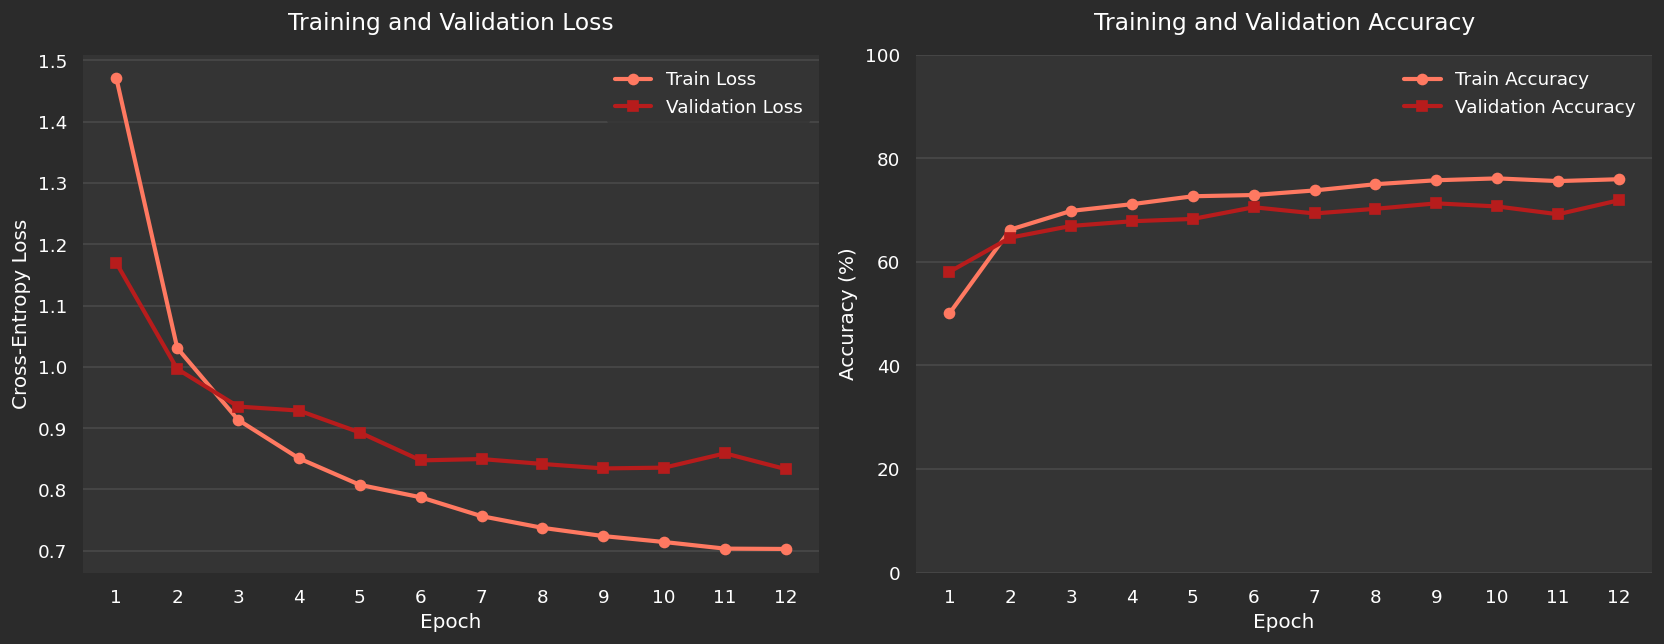

In [11]:

import copy
import time

EPOCHS = 12
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
PATIENCE = 4

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

def run_epoch(model, loader, optimizer=None):
    is_training = optimizer is not None

    model.eval()

    if is_training:
        model.fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(
            device, non_blocking=True
        )
        labels = labels.to(
            device, non_blocking=True
        )

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        correct += (predictions == labels).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

print("Training functions initialized")

model.fc.reset_parameters()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Классификатор и оптимизатор переинициализированы.")

history = {
    "train_loss": [],
    "validation_loss": [],
    "train_accuracy": [],
    "validation_accuracy": []
}

best_val_loss = float("inf")
best_epoch = 0
best_weights = None
epochs_without_improvement = 0

checkpoint_path = "/content/mushrooms_resnet18_best.pth"

print("Starting ResNet18 training...\n")

for epoch in range(EPOCHS):

    start_time = time.time()

    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        optimizer
    )

    validation_loss, validation_accuracy = run_epoch(
        model,
        validation_loader
    )

    history["train_loss"].append(train_loss)
    history["validation_loss"].append(validation_loss)

    history["train_accuracy"].append(train_acc)
    history["validation_accuracy"].append(validation_accuracy)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {validation_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Acc: {validation_accuracy:.2%}"
    )

    if validation_loss < best_val_loss - 1e-4:

        best_val_loss = validation_loss
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(
            model.state_dict()
        )

        torch.save({
            "model_state_dict": best_weights,
            "class_names": class_names,
            "num_classes": num_classes,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss
        }, checkpoint_path)

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping activated")
        break

model.load_state_dict(best_weights)
model.eval()

print("\nTraining completed")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", checkpoint_path)

epochs = np.arange(
    1, len(history["train_loss"]) + 1
)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.5)
)

fig.patch.set_facecolor("#2b2b2b")

for ax in axes:
    ax.set_facecolor("#343434")
    ax.grid(axis="y", color="white", alpha=0.10)
    ax.grid(axis="x", visible=False)

    ax.tick_params(colors="white")

    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].plot(
    epochs,
    history["train_loss"],
    color="#ff7961",
    linewidth=2.5,
    marker="o",
    label="Train Loss"
)

axes[0].plot(
    epochs,
    history["validation_loss"],
    color="#b71c1c",
    linewidth=2.5,
    marker="s",
    label="Validation Loss"
)

axes[0].set_title(
    "Training and Validation Loss",
    color="white",
    pad=15
)

axes[0].set_xlabel("Epoch", color="white")
axes[0].set_ylabel("Cross-Entropy Loss", color="white")

axes[1].plot(
    epochs,
    np.array(history["train_accuracy"]) * 100,
    color="#ff7961",
    linewidth=2.5,
    marker="o",
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    np.array(history["validation_accuracy"]) * 100,
    color="#b71c1c",
    linewidth=2.5,
    marker="s",
    label="Validation Accuracy"
)

axes[1].set_title(
    "Training and Validation Accuracy",
    color="white",
    pad=15
)

axes[1].set_xlabel("Epoch", color="white")
axes[1].set_ylabel("Accuracy (%)", color="white")
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.set_xticks(epochs)
    legend = ax.legend(
        facecolor="#343434",
        edgecolor="none"
    )
    for text in legend.get_texts():
        text.set_color("white")

plt.tight_layout()
plt.show()

 Методика Fine-Tuning

In [12]:

import copy

stage1_weights = copy.deepcopy(model.state_dict())
stage1_val_loss = best_val_loss

for param in model.layer4.parameters():
    param.requires_grad = True


finetune_optimizer = torch.optim.Adam(
    [
        {
            "params": model.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

FINETUNE_EPOCHS = 6

print("Fine-Tuning configured")
print("Trainable parameters:", sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
))

Fine-Tuning configured
Trainable parameters: 8398345


Проведение дополнительного обучения

Starting Fine-Tuning...

Epoch 01/6 | Train Loss: 0.6381 | Val Loss: 0.8046 | Train Acc: 77.54% | Val Acc: 73.68%
Epoch 02/6 | Train Loss: 0.5674 | Val Loss: 0.7567 | Train Acc: 80.85% | Val Acc: 75.34%
Epoch 03/6 | Train Loss: 0.4978 | Val Loss: 0.7225 | Train Acc: 82.10% | Val Acc: 76.69%
Epoch 04/6 | Train Loss: 0.4403 | Val Loss: 0.6940 | Train Acc: 85.25% | Val Acc: 77.14%
Epoch 05/6 | Train Loss: 0.3991 | Val Loss: 0.6975 | Train Acc: 86.11% | Val Acc: 77.29%
Epoch 06/6 | Train Loss: 0.3560 | Val Loss: 0.7567 | Train Acc: 87.64% | Val Acc: 75.64%

Fine-Tuning completed
Best Fine-Tuning epoch: 4
Best Validation Loss: 0.694
Checkpoint: /content/mushrooms_resnet18_final.pth


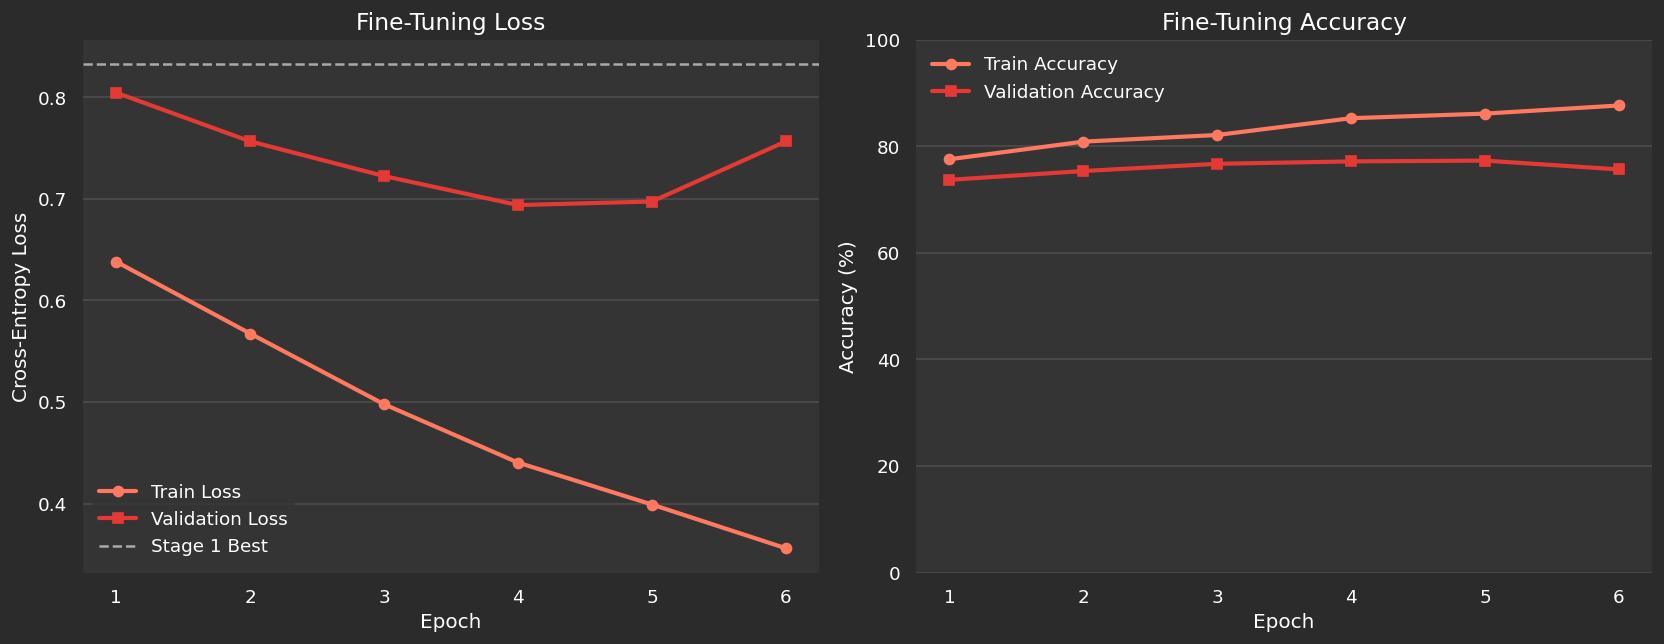

In [13]:

finetune_history = {
    "train_loss": [],
    "validation_loss": [],
    "train_accuracy": [],
    "validation_accuracy": []
}

best_ft_loss = stage1_val_loss
best_ft_weights = copy.deepcopy(stage1_weights)

best_ft_epoch = 0
epochs_without_improvement = 0
FT_PATIENCE = 3

print("Starting Fine-Tuning...\n")

for epoch in range(FINETUNE_EPOCHS):

    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        finetune_optimizer
    )

    validation_loss, validation_accuracy = run_epoch(
        model,
        validation_loader
    )

    finetune_history["train_loss"].append(train_loss)
    finetune_history["validation_loss"].append(validation_loss)

    finetune_history["train_accuracy"].append(train_acc)
    finetune_history["validation_accuracy"].append(validation_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{FINETUNE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {validation_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Acc: {validation_accuracy:.2%}"
    )

    if validation_loss < best_ft_loss - 1e-4:

        best_ft_loss = validation_loss
        best_ft_epoch = epoch + 1

        best_ft_weights = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= FT_PATIENCE:
        print("\nEarly stopping activated")
        break

model.load_state_dict(best_ft_weights)
model.eval()

final_checkpoint = "/content/mushrooms_resnet18_final.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "num_classes": num_classes,
    "best_val_loss": best_ft_loss,
    "best_ft_epoch": best_ft_epoch,
    "architecture": "ResNet18"
}, final_checkpoint)

print("\nFine-Tuning completed")

if best_ft_epoch == 0:
    print("Сохранена модель первого этапа")
else:
    print("Best Fine-Tuning epoch:", best_ft_epoch)

print("Best Validation Loss:", round(best_ft_loss, 4))
print("Checkpoint:", final_checkpoint)

ft_epochs = np.arange(
    1,
    len(finetune_history["train_loss"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.patch.set_facecolor("#2b2b2b")

for ax in axes:
    ax.set_facecolor("#343434")
    ax.tick_params(colors="white")
    ax.grid(axis="y", alpha=0.12, color="white")
    ax.grid(axis="x", visible=False)

    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].plot(
    ft_epochs,
    finetune_history["train_loss"],
    color="#ff7961",
    marker="o",
    linewidth=2.5,
    label="Train Loss"
)

axes[0].plot(
    ft_epochs,
    finetune_history["validation_loss"],
    color="#e53935",
    marker="s",
    linewidth=2.5,
    label="Validation Loss"
)

axes[0].axhline(
    stage1_val_loss,
    color="#aaaaaa",
    linestyle="--",
    linewidth=1.5,
    label="Stage 1 Best"
)

axes[0].set_title("Fine-Tuning Loss", color="white")
axes[0].set_xlabel("Epoch", color="white")
axes[0].set_ylabel("Cross-Entropy Loss", color="white")

axes[1].plot(
    ft_epochs,
    np.array(finetune_history["train_accuracy"]) * 100,
    color="#ff7961",
    marker="o",
    linewidth=2.5,
    label="Train Accuracy"
)

axes[1].plot(
    ft_epochs,
    np.array(finetune_history["validation_accuracy"]) * 100,
    color="#e53935",
    marker="s",
    linewidth=2.5,
    label="Validation Accuracy"
)

axes[1].set_title("Fine-Tuning Accuracy", color="white")
axes[1].set_xlabel("Epoch", color="white")
axes[1].set_ylabel("Accuracy (%)", color="white")
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.set_xticks(ft_epochs)
    legend = ax.legend(
        facecolor="#343434",
        edgecolor="none"
    )
    for label in legend.get_texts():
        label.set_color("white")

plt.tight_layout()
plt.show()

Оценка качества классификации


,Dataset,Images,Loss,Accuracy (%)
0,Train,4983,0.4034,85.83
1,Validation,665,0.6940,77.14
2,Test,996,0.6341,78.01



Final Test Accuracy: 78.01%


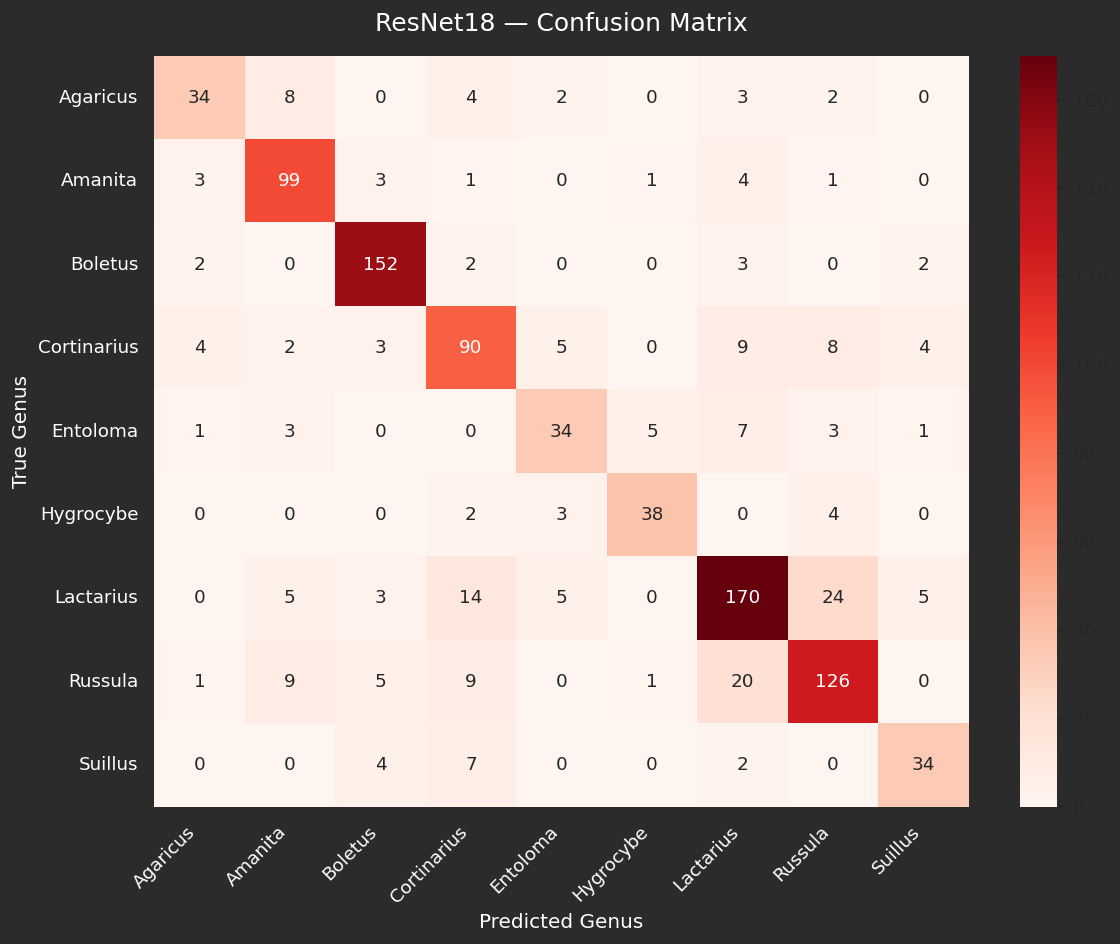

Classification Report:

              precision    recall  f1-score   support

    Agaricus     0.7556    0.6415    0.6939        53
     Amanita     0.7857    0.8839    0.8319       112
     Boletus     0.8941    0.9441    0.9184       161
 Cortinarius     0.6977    0.7200    0.7087       125
    Entoloma     0.6939    0.6296    0.6602        54
   Hygrocybe     0.8444    0.8085    0.8261        47
   Lactarius     0.7798    0.7522    0.7658       226
     Russula     0.7500    0.7368    0.7434       171
     Suillus     0.7391    0.7234    0.7312        47

    accuracy                         0.7801       996
   macro avg     0.7711    0.7600    0.7644       996
weighted avg     0.7787    0.7801    0.7785       996



In [14]:


train_eval_dataset = MushroomSubset(
    mushroom_dataset,
    train_idx,
    eval_transform
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

model.eval()

train_loss, train_acc = run_epoch(
    model, train_eval_loader
)

validation_loss, validation_accuracy = run_epoch(
    model, validation_loader
)

test_loss, test_acc = run_epoch(
    model, test_loader
)

results_df = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Images": [
        len(train_dataset),
        len(validation_dataset),
        len(test_dataset)
    ],
    "Loss": [train_loss, validation_loss, test_loss],
    "Accuracy (%)": [
        train_acc * 100,
        validation_accuracy * 100,
        test_acc * 100
    ]
})

display(
    results_df.style.format({
        "Loss": "{:.4f}",
        "Accuracy (%)": "{:.2f}"
    })
)

print(f"\nFinal Test Accuracy: {test_acc:.2%}")

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

y_true = []
y_pred = []

model.eval()

with torch.inference_mode():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(
            predictions.cpu().numpy().tolist()
        )

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

fig, ax = plt.subplots(figsize=(10, 8))

fig.patch.set_facecolor("#2b2b2b")
ax.set_facecolor("#343434")

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0,
    ax=ax
)

ax.set_title(
    "ResNet18 — Confusion Matrix",
    color="white",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Predicted Genus", color="white")
ax.set_ylabel("True Genus", color="white")

ax.tick_params(axis="both", colors="white")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

Визуализация результатов классификации

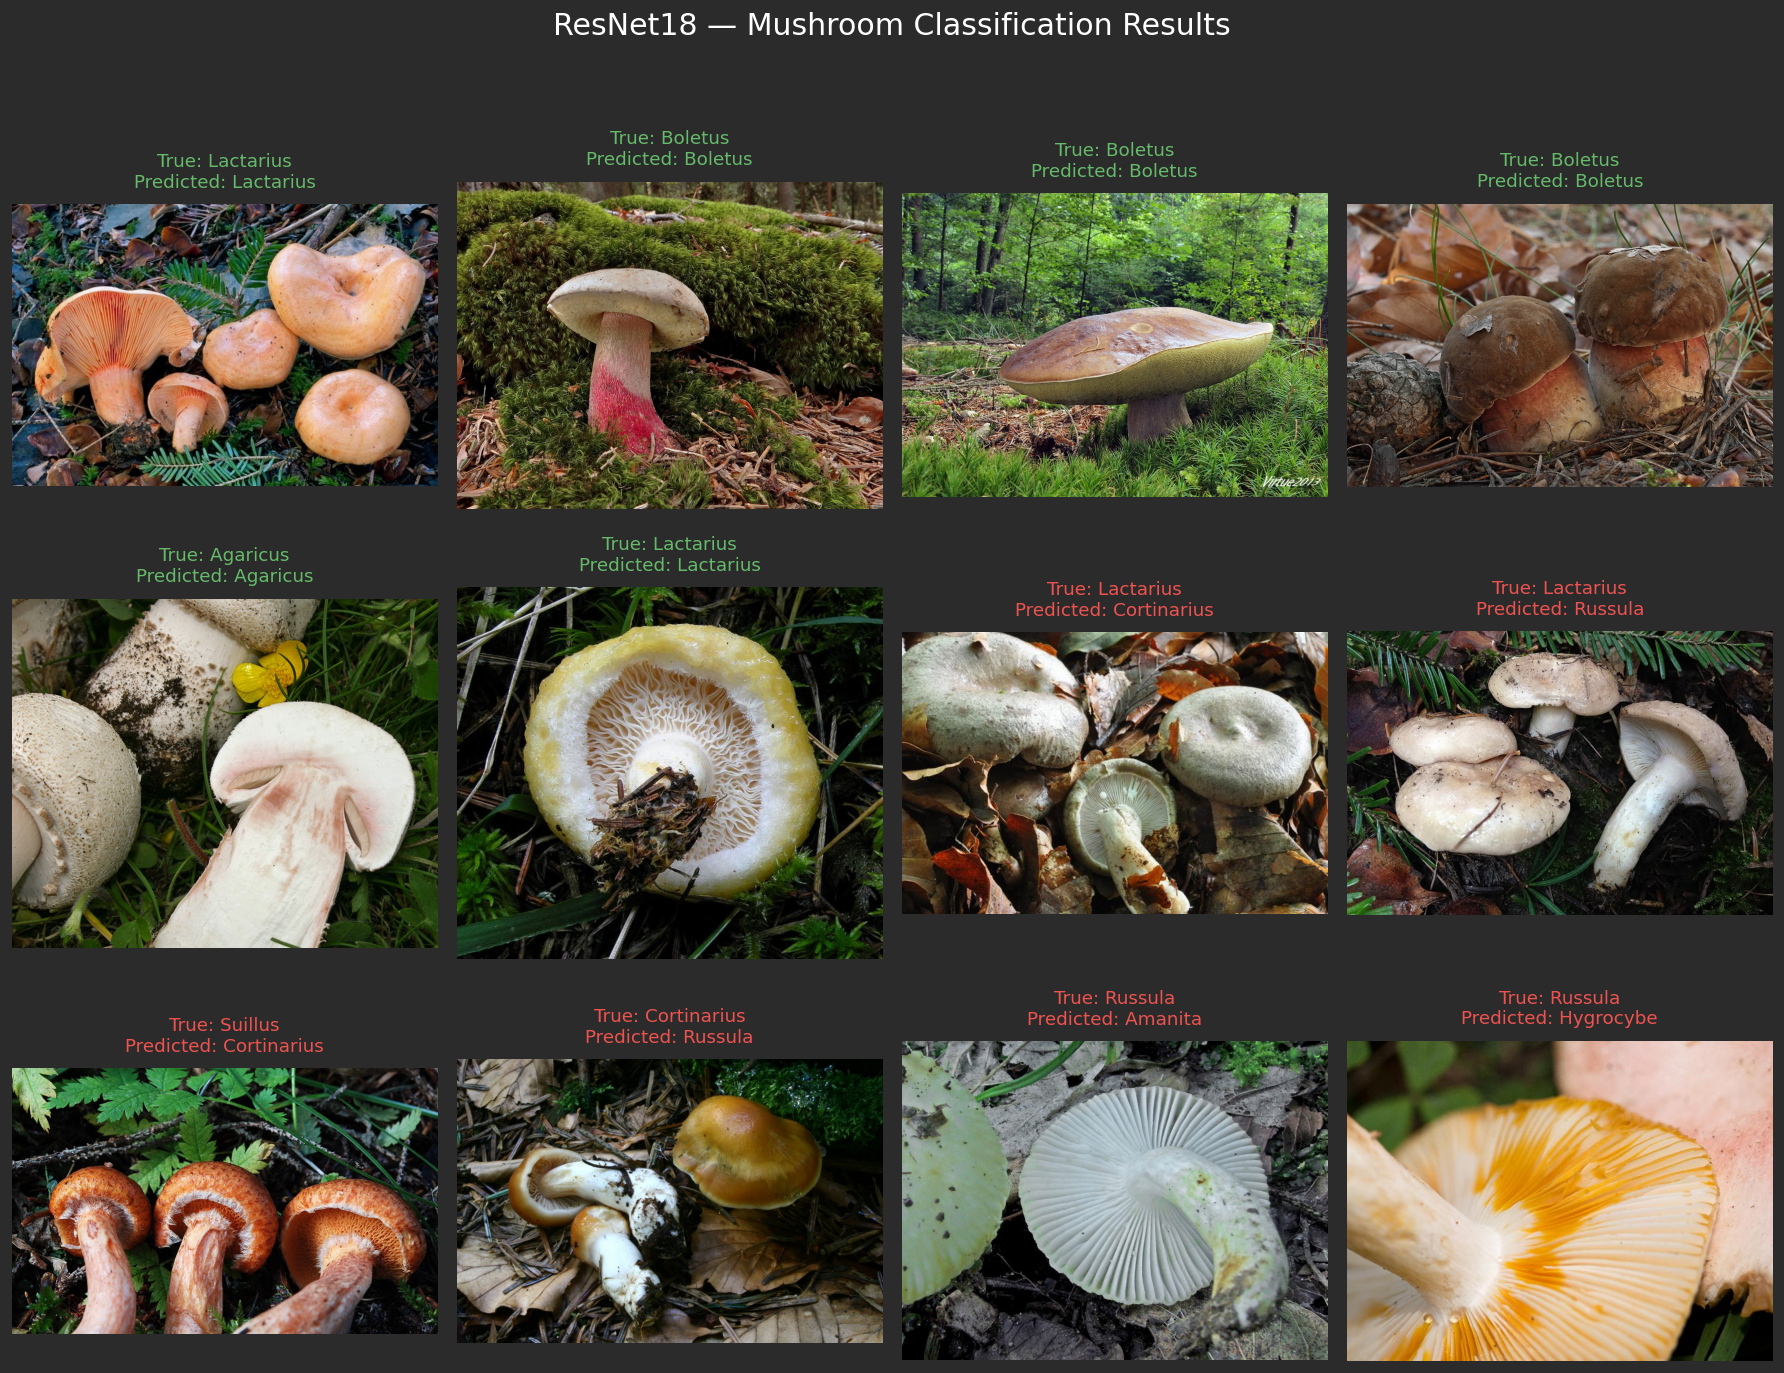

In [15]:


import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

y_true_arr = np.array(y_true)
y_pred_arr = np.array(y_pred)

correct_indices = np.where(
    y_true_arr == y_pred_arr
)[0]

incorrect_indices = np.where(
    y_true_arr != y_pred_arr
)[0]

rng = np.random.default_rng(RANDOM_STATE)

selected_correct = rng.choice(
    correct_indices,
    size=min(6, len(correct_indices)),
    replace=False
)

selected_incorrect = rng.choice(
    incorrect_indices,
    size=min(6, len(incorrect_indices)),
    replace=False
)

selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

fig, axes = plt.subplots(
    3, 4, figsize=(15, 12)
)

fig.patch.set_facecolor("#2b2b2b")

for ax, idx in zip(axes.flat, selected_indices):

    original_idx = int(test_dataset.indices[idx])

    path, label = mushroom_dataset.samples[
        original_idx
    ]

    with Image.open(path) as img:
        image = img.convert("RGB").copy()

    predicted = int(y_pred_arr[idx])
    actual = int(y_true_arr[idx])

    correct = predicted == actual

    color = "#66bb6a" if correct else "#ef5350"

    ax.imshow(image)
    ax.set_title(
        f"True: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}",
        fontsize=11,
        color=color,
        pad=10
    )

    ax.axis("off")

for ax in axes.flat[len(selected_indices):]:
    ax.axis("off")

plt.suptitle(
    "ResNet18 — Mushroom Classification Results",
    fontsize=18,
    color="white",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()